# IDEF 2022/2023: análise exploratória
Como se reparte a despesa das famílias em Portugal? E como muda esse orçamento de região para região e entre famílias com rendimentos diferentes?

Este notebook usa as tabelas arrumadas no notebook 1 (`data/processed/`) e responde a quatro perguntas, cada uma com um gráfico:

1. Como se distribui, em geral, o orçamento das famílias?
2. Onde é que cada região se afasta da média nacional?
3. Como muda a estrutura do orçamento com o rendimento?
4. Quanto mais gasta o 5.º quintil do que o 1.º, em cada categoria?

Em todas uso só os **13 categorias principais da COICOP**, a classificação que agrupa as despesas por finalidade, como alimentação, habitação e transportes.. Na secção regional, duas tabelas detalham a habitação e comparam três tratamentos da renda. Nos grupos de topo não há valores marcados como pouco fiáveis (§), e só falta um valor: Serviços de educação no Alentejo.

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

cwd = Path.cwd()
root = cwd.parent if cwd.name == "notebooks" else cwd
data = root / "data"

PROC = data / "processed"


NOMES = {
    "01": "Alimentação",
    "02": "Álcool e tabaco",
    "03": "Vestuário e calçado",
    "04": "Habitação",
    "05": "Equipamento doméstico",
    "06": "Saúde",
    "07": "Transportes",
    "08": "Comunicação",
    "09": "Lazer e cultura",
    "10": "Educação",
    "11": "Restaurantes e alojamento",
    "12": "Seguros e serv. financeiros",
    "13": "Cuidados pessoais e outros",
}

def topo(df):
    df = df[df.nivel == 1].copy()
    df["categoria"] = df.coicop.map(NOMES)
    return df

dados_regiao = pd.read_csv(PROC / "despesa_por_regiao.csv", dtype={"coicop": str})
dados_quintil = pd.read_csv(PROC / "despesa_por_quintil.csv", dtype={"coicop": str})
regiao = topo(dados_regiao)
quintil = topo(dados_quintil)

# Verificação: sem valores pouco fiáveis nos grupos de topo
print("pouco fiáveis (região):", int((regiao.baixa_fiab_pct | regiao.baixa_fiab_eur).sum()))
print("pouco fiáveis (quintil):", int((quintil.baixa_fiab_pct | quintil.baixa_fiab_eur).sum()))
print("em falta:", regiao.peso_pct.isna().sum(), "(região),", quintil.peso_pct.isna().sum(), "(quintil)")

pouco fiáveis (região): 0
pouco fiáveis (quintil): 0
em falta: 1 (região), 0 (quintil)


## 1. Como gastam as famílias portuguesas, em geral?

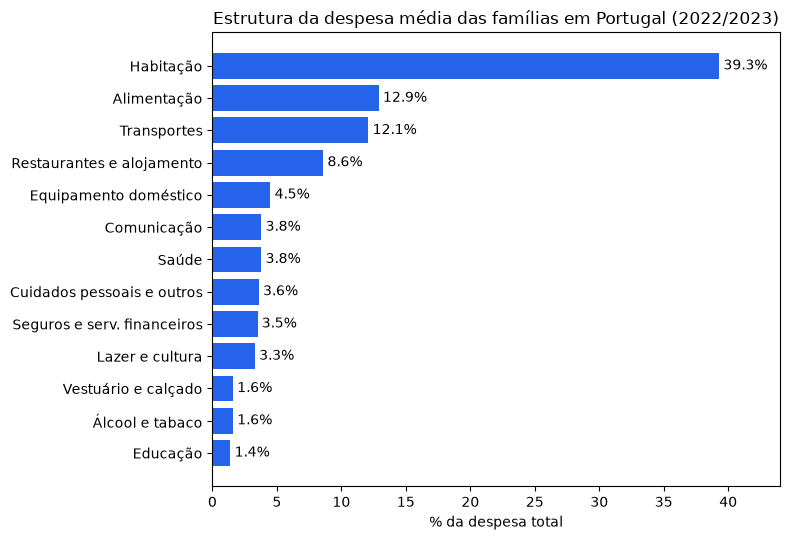

As 3 maiores categorias (Habitação, Alimentação, Transportes) somam 64.3% da despesa.


In [2]:
pt = (regiao[regiao.grupo == "Portugal"]
      .set_index("categoria")["peso_pct"].sort_values())

fig, ax = plt.subplots(figsize=(8, 5.5))
barras = ax.barh(pt.index, pt.values, color="#2563eb")
ax.bar_label(barras, labels=[f"{v:.1f}%" for v in pt.values], padding=3)
ax.set_xlabel("% da despesa total")
ax.set_title("Estrutura da despesa média das famílias em Portugal (2022/2023)")
ax.set_xlim(0, pt.max() * 1.12)
plt.tight_layout()
plt.show()

top3 = pt.sort_values(ascending=False).head(3)
print(f"As 3 maiores categorias ({', '.join(top3.index)}) somam {top3.sum():.1f}% da despesa.")

## 2. Onde é que as regiões se afastam da média?
O gráfico mostra quanto cada categoria pesa a mais ou a menos face à média nacional. Por exemplo, a habitação representa 43,8% da despesa em Lisboa e 39,3% no país. A diferença é de 4,5 pontos percentuais (pp). A célula vazia corresponde à educação no Alentejo, cujo valor está indisponível. O Continente fica de fora porque agrega várias regiões.

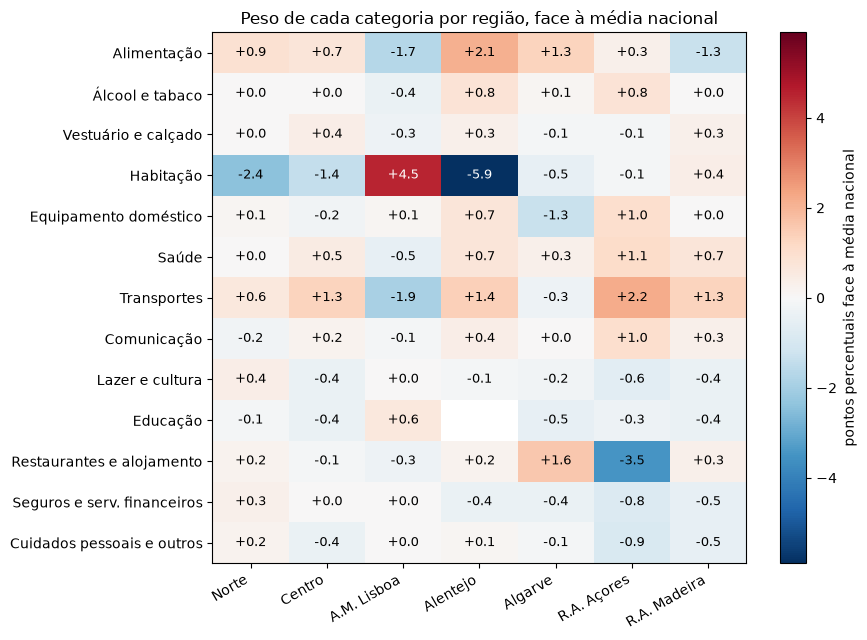

In [3]:
ordem_regioes = ["Norte", "Centro", "A.M. Lisboa", "Alentejo", "Algarve", "R.A. Açores", "R.A. Madeira"]

p = regiao.pivot(index="categoria", columns="grupo", values="peso_pct")
desvio = p[ordem_regioes].sub(p["Portugal"], axis=0)
desvio = desvio.loc[[NOMES[k] for k in NOMES]]   # ordem COICOP

lim = np.nanmax(np.abs(desvio.values))
fig, ax = plt.subplots(figsize=(9, 6.5))
im = ax.imshow(desvio.values, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(len(desvio.columns)), desvio.columns, rotation=30, ha="right")
ax.set_yticks(range(len(desvio.index)), desvio.index)

for i in range(desvio.shape[0]):
    for j in range(desvio.shape[1]):
        v = desvio.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=9,
                    color="white" if abs(v) > lim * 0.6 else "black")

cb = fig.colorbar(im, ax=ax)
cb.set_label("pontos percentuais face à média nacional")
ax.set_title("Peso de cada categoria por região, face à média nacional")
plt.tight_layout()
plt.show()

In [4]:
# Os 5 maiores desvios (em valor absoluto), para ler sem procurar no gráfico
maiores = (desvio.stack().rename("pp").reset_index()
           .rename(columns={"grupo": "regiao"}))
maiores = maiores.reindex(maiores.pp.abs().sort_values(ascending=False).index).head(5)
maiores.round(1)

,categoria,regiao,pp
24,Habitação,Alentejo,-5.9
23,Habitação,A.M. Lisboa,4.5
75,Restaurantes e alojamento,R.A. Açores,-3.5
21,Habitação,Norte,-2.4
47,Transportes,R.A. Açores,2.2


In [5]:
# Contexto: despesa total anual média por região (€)
tot_reg = (dados_regiao
           .query("nivel == 0").set_index("grupo")["despesa_eur"]
           .loc[["Portugal"] + ordem_regioes].sort_values(ascending=False))
tot_reg

grupo
A.M. Lisboa     26891.0
Algarve         24432.0
Portugal        23900.0
Norte           23245.0
R.A. Madeira    22605.0
Centro          22222.0
Alentejo        21359.0
R.A. Açores     19431.0
Name: despesa_eur, dtype: float64

### De que é feita a despesa em habitação?
A divisão 04 tem cinco componentes. A tabela mostra euros por agregado e por ano e a percentagem da despesa total em Portugal. Quanto custaria arrendar a casa onde vives? O INE pediu essa estimativa às famílias que vivem em casa própria ou cedida, incluindo alojamento recebido como salário em espécie. O valor entra na despesa com o nome de renda subjetiva (04.2).

Fonte: INE, quadros Q.2.1.a e Q.2.1.b, e Inquérito às Despesas das Famílias 2022/2023, pp. 8 e 36.

In [6]:
codigos_habitacao = ["04.1", "04.2", "04.3", "04.4", "04.5"]
componentes = dados_regiao.loc[
    dados_regiao.grupo.eq("Portugal") & dados_regiao.coicop.isin(codigos_habitacao),
    ["coicop", "descricao", "despesa_eur", "peso_pct"],
].set_index("coicop").loc[codigos_habitacao]

tabela_componentes = componentes.rename(columns={"descricao": "Componente"})
tabela_componentes["€/ano por agregado"] = tabela_componentes.pop("despesa_eur").map(
    lambda valor: f"{valor:.0f}"
)
tabela_componentes["% da despesa total"] = tabela_componentes.pop("peso_pct").map(
    lambda valor: f"{valor:.1f}%".replace(".", ",")
)
tabela_componentes

,Componente,€/ano por agregado,% da despesa total
coicop,,,
04.1,Rendas efetivas da habitação,818,"3,4%"
04.2,Rendas subjetivas da habitação,6539,"27,4%"
04.3,"Manutenção, reparação e segurança das habitações",317,"1,3%"
04.4,Abastecimento de água e serviços diversos rela...,548,"2,3%"
04.5,"Eletricidade, gás e outros combustíveis",1168,"4,9%"


### Quanto pesa a habitação com cada tratamento da renda?
- **Com renda subjetiva.** Peso publicado nos quadros do INE.
- **Com renda imputada.** O INE estima quanto custaria arrendar a habitação usando um modelo estatístico que tem em conta características da casa. Essa estimativa substitui a das famílias no cálculo do peso da habitação e da despesa total. Na publicação, o INE chama-lhe modelo de preços hedónicos.
- **Sem renda subjetiva.** Subtraio a rubrica 04.2 da habitação e do total antes de calcular o peso. As restantes despesas não monetárias, como o autoconsumo, continuam incluídas.

O quadro compara as sete regiões NUTS II da versão de 2013 e usa Portugal como referência. A diferença Lisboa − Alentejo está em pontos percentuais.

Fonte dos montantes imputados: INE, Inquérito às Despesas das Famílias 2022/2023, p. 36. Os restantes valores vêm dos quadros Q.2.1.a e Q.2.1.b.

In [7]:
# Transcrição da p. 36 do INE, em euros anuais médios por agregado.
imputada = pd.DataFrame.from_dict({
    "Portugal": (7492, 22002),
    "Norte": (6753, 21422),
    "Centro": (7249, 21050),
    "A.M. Lisboa": (8832, 23956),
    "Alentejo": (6428, 20662),
    "Algarve": (8091, 23039),
    "R.A. Açores": (6518, 18328),
    "R.A. Madeira": (6660, 20290),
}, orient="index", columns=["habitação", "total"])

euros = dados_regiao.pivot(index="grupo", columns="coicop", values="despesa_eur")
renda_subjetiva = euros["04.2"]
peso_publicado = regiao.loc[regiao.coicop.eq("04")].set_index("grupo")["peso_pct"]

cenarios = pd.DataFrame({
    "Com renda subjetiva": peso_publicado,
    "Com renda imputada": 100 * imputada["habitação"] / imputada["total"],
    "Sem renda subjetiva": 100 * (euros["04"] - renda_subjetiva)
                         / (euros["TOTAL"] - renda_subjetiva),
}).loc[["Portugal", *ordem_regioes]]
# cenarios = cenarios.round(1)
diferenca = cenarios.loc["A.M. Lisboa"] - cenarios.loc["Alentejo"]
tabela_cenarios = cenarios.apply(
    lambda coluna: coluna.map(lambda valor: f"{valor:.1f}%".replace(".", ","))
)
tabela_cenarios.loc["Lisboa - Alentejo"] = diferenca.map(
    lambda valor: f"{valor:.1f} pp".replace(".", ",")
)
tabela_cenarios

,Com renda subjetiva,Com renda imputada,Sem renda subjetiva
Portugal,"39,3%","34,1%","16,4%"
Norte,"36,9%","31,5%","16,3%"
Centro,"37,9%","34,4%","15,1%"
A.M. Lisboa,"43,8%","36,9%","18,0%"
Alentejo,"33,4%","31,1%","14,6%"
Algarve,"38,8%","35,1%","15,8%"
R.A. Açores,"39,2%","35,6%","16,7%"
R.A. Madeira,"39,7%","32,8%","15,2%"
Lisboa - Alentejo,"10,4 pp","5,8 pp","3,4 pp"


Em Portugal, a habitação representa 39,3% da despesa com a renda estimada pelas famílias, 34,1% com a estimativa do INE e 16,4% quando se retira a renda subjetiva. Lisboa fica em primeiro nos três cenários, mas a distância face ao Alentejo cai de 10,4 para 3,4 pontos percentuais entre o primeiro e o último.

## 3. Como muda o orçamento com o rendimento?
As famílias são ordenadas pelo rendimento de 2021, ajustado ao tamanho e à composição do agregado, e divididas em cinco grupos. Cada grupo chama-se quintil. O primeiro reúne os 20% com menor rendimento ajustado e o quinto os 20% com maior rendimento ajustado.

Cada gráfico mostra o peso de uma categoria ao longo dos cinco quintis. As escalas verticais são diferentes em cada gráfico, para se ver bem a forma de cada curva.

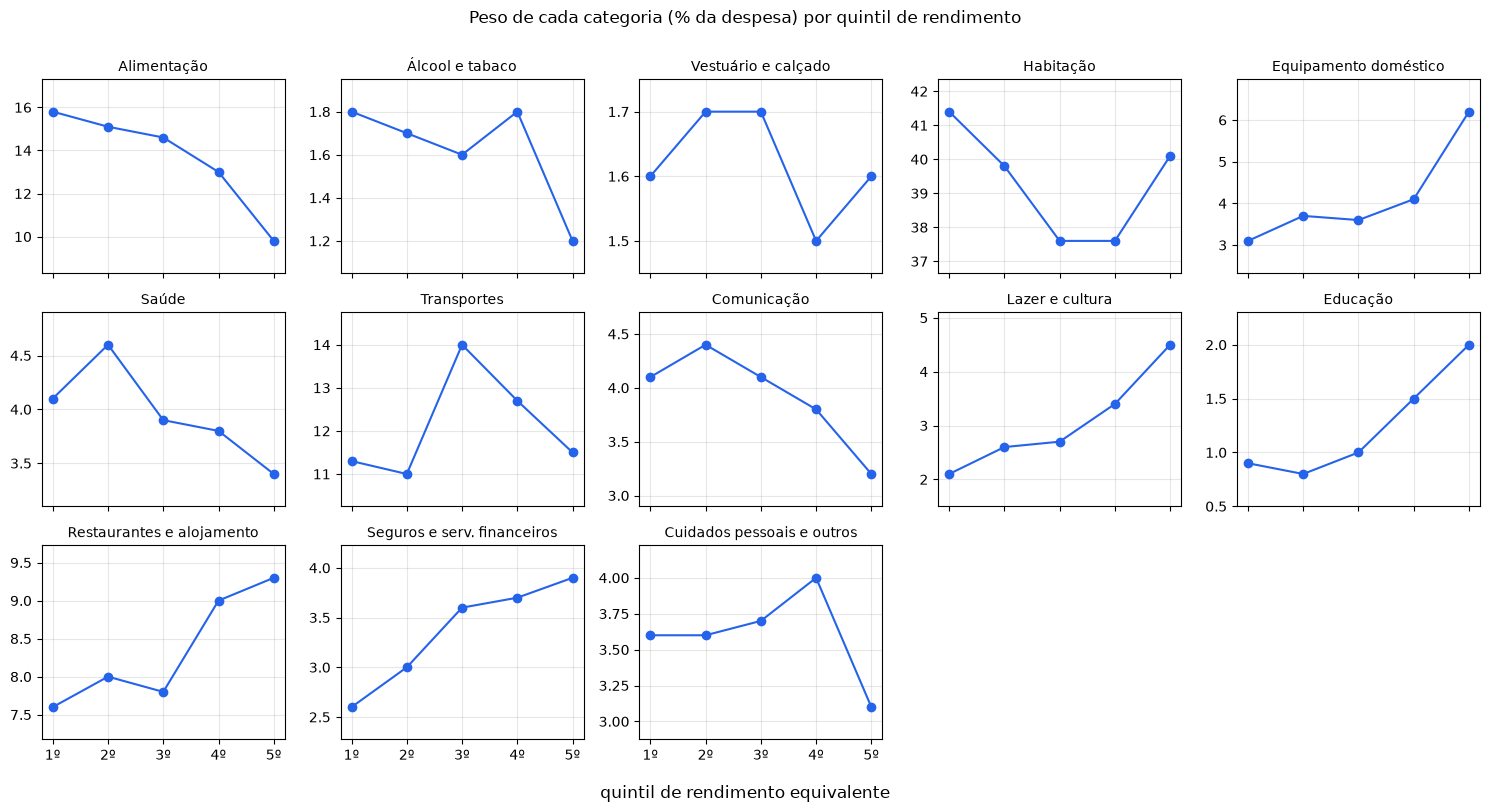

In [8]:
quintis = ["1º quintil", "2º quintil", "3º quintil", "4º quintil", "5º quintil"]
pq = (quintil.pivot(index="categoria", columns="grupo", values="peso_pct")[quintis]
      .loc[[NOMES[k] for k in NOMES]])

fig, axes = plt.subplots(3, 5, figsize=(15, 8), sharex=True)
for ax, (cat, linha) in zip(axes.flat, pq.iterrows()):
    ax.plot(range(5), linha.values, marker="o", color="#2563eb")
    ax.set_title(cat, fontsize=10)
    ax.set_xticks(range(5), ["1º", "2º", "3º", "4º", "5º"])
    ax.margins(y=0.25)
    ax.grid(alpha=0.3)
for ax in list(axes.flat)[len(pq):]:
    ax.axis("off")
fig.suptitle("Peso de cada categoria (% da despesa) por quintil de rendimento", y=1.0)
fig.supxlabel("quintil de rendimento equivalente")
plt.tight_layout()
plt.show()

In [9]:
comp = pd.DataFrame({
    "1º quintil": pq["1º quintil"], "5º quintil": pq["5º quintil"],
})
comp["dif_pp"] = (comp["5º quintil"] - comp["1º quintil"]).round(1)
comp.sort_values("dif_pp")

,1º quintil,5º quintil,dif_pp
categoria,,,
Alimentação,15.8,9.8,-6.0
Habitação,41.4,40.1,-1.3
Comunicação,4.1,3.2,-0.9
Saúde,4.1,3.4,-0.7
Álcool e tabaco,1.8,1.2,-0.6
Cuidados pessoais e outros,3.6,3.1,-0.5
Vestuário e calçado,1.6,1.6,0.0
Transportes,11.3,11.5,0.2
Educação,0.9,2.0,1.1


## 4. Quanto mais gasta o 5.º quintil do que o 1.º?
Aqui já são **euros**, não percentagens. O rácio é a despesa anual média do 5.º quintil a dividir pela do 1.º. Perto de 1 quer dizer que gastam quase o mesmo, e valores altos quer dizer que a categoria cresce muito com o rendimento. A linha a tracejado é o rácio da despesa total.

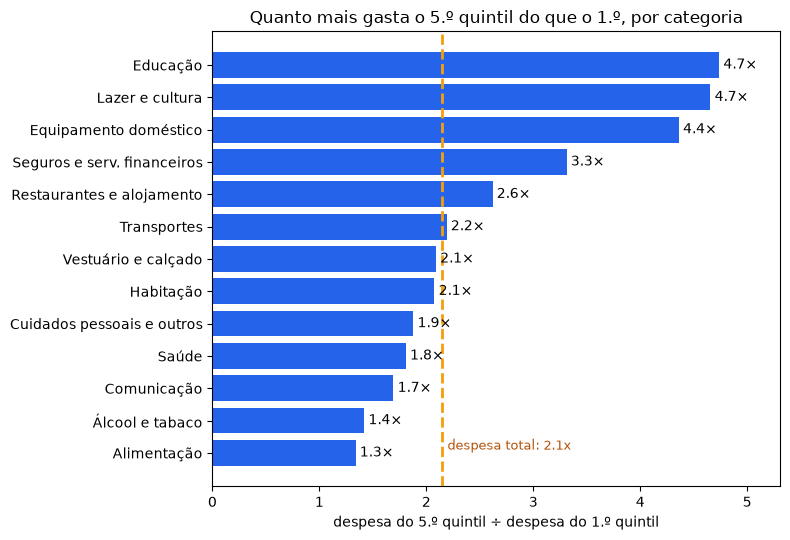

In [10]:
eq = quintil.pivot(index="categoria", columns="grupo", values="despesa_eur")
racio = (eq["5º quintil"] / eq["1º quintil"]).sort_values()

tot = (dados_quintil
       .query("nivel == 0").set_index("grupo")["despesa_eur"])
racio_total = tot["5º quintil"] / tot["1º quintil"]

fig, ax = plt.subplots(figsize=(8, 5.5))
barras = ax.barh(racio.index, racio.values, color="#2563eb")
ax.bar_label(barras, labels=[f"{v:.1f}×" for v in racio.values], padding=3)
ax.axvline(racio_total, color="#f59e0b", linestyle="--", linewidth=2)
ax.text(racio_total + 0.05, 0.1, f"despesa total: {racio_total:.1f}x", color="#b45309", fontsize=9)
ax.set_xlabel("despesa do 5.º quintil ÷ despesa do 1.º quintil")
ax.set_title("Quanto mais gasta o 5.º quintil do que o 1.º, por categoria")
ax.set_xlim(0, racio.max() * 1.12)
plt.tight_layout()
plt.show()

No quinto quintil, a alimentação ocupa uma fatia menor do orçamento do que no primeiro (9,8% face a 15,8%). Em euros, a despesa média com alimentação é cerca de 30% superior. A fatia diminui porque a despesa total aumenta mais do que a despesa com alimentação.

## 5. Conclusões
A forma de valorizar a renda influencia tanto o peso nacional da habitação como a distância entre regiões. Lisboa lidera nos três cenários, mas a dimensão da diferença face ao Alentejo depende do tratamento da renda.

As comparações por rendimento mostram duas coisas diferentes: quanto se gasta em euros e que fatia do orçamento esse gasto representa. A alimentação é o exemplo mais claro. A habitação segue outro padrão: perde peso até aos quintis intermédios e volta a ganhar peso no último.

**Limitações:** 

- Os quintis usam o rendimento de 2021. A recolha decorreu entre fevereiro de 2022 e fevereiro de 2023, num período de inflação elevada. Os períodos de referência das despesas variam por rubrica.
- O dimensionamento da amostra visou erros relativos máximos *a priori* de 10% no Norte e em Lisboa, 15% no Centro, Algarve e Madeira, e 18% no Alentejo e nos Açores, por divisão da COICOP e excluindo educação. As diferenças regionais pequenas devem ser lidas com cautela. Estes limites de planeamento não quantificam a incerteza de cada diferença em pontos percentuais.
- O INE recomenda cautela para coeficientes de variação a partir de 20% e não publica estimativas acima de 30%. *(O coeficiente de variação mede a incerteza de uma estimativa em relação ao seu valor. Quanto maior for, mais cautela exige a leitura.)*  A taxa de resposta foi de 59% e o desenho amostral incluiu um reforço de alojamentos associados a rendimentos elevados.
- Os pesos são rácios de despesas médias do grupo. No país, 76% dos agregados viviam em casa própria, 16% em casa arrendada e 8% em casa cedida ou recebida como salário em espécie.

## Próximos passos
- Notebook 3: carregar os CSV numa base SQLite e responder a 3 ou 4 destas perguntas com SQL
- Opcional: dashboard com 3 a 5 visuais